In [14]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/playground-series-s6e2/sample_submission.csv
/kaggle/input/playground-series-s6e2/train.csv
/kaggle/input/playground-series-s6e2/test.csv


In [15]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, roc_auc_score
from sklearn.metrics import precision_score, recall_score, f1_score
import warnings
warnings.filterwarnings('ignore')

In [16]:
data_comp = pd.read_csv("/kaggle/input/playground-series-s6e2/train.csv")

In [17]:
data_comp

,id,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,0,58,1,4,152,239,0,0,158,1,3.6,2,2,7,Presence
1,1,52,1,1,125,325,0,2,171,0,0.0,1,0,3,Absence
2,2,56,0,2,160,188,0,2,151,0,0.0,1,0,3,Absence
3,3,44,0,3,134,229,0,2,150,0,1.0,2,0,3,Absence
4,4,58,1,4,140,234,0,2,125,1,3.8,2,3,3,Presence
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
629995,629995,56,0,1,110,226,0,0,132,0,0.0,1,0,7,Absence
629996,629996,54,1,4,128,249,1,2,150,0,0.0,2,0,3,Absence
629997,629997,67,1,4,130,275,0,0,149,0,0.0,1,2,7,Presence
629998,629998,52,1,4,140,199,0,2,157,0,0.0,1,0,6,Presence


In [18]:
# Data Visualization
print("=" * 60)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 60)

# General information
print("\n📊 Dataset Information:")
print(f"  - Total records: {len(data_comp):,}")
print(f"  - Total features: {data_comp.shape[1] - 2}")  # Minus id and target
print(f"  - Null values: {data_comp.isnull().sum().sum()}")

# Target variable distribution
print("\n❤️ Heart Disease Distribution (before mapping):")
print(data_comp["Heart Disease"].value_counts())

# Map target variable
data_comp["Heart Disease"] = data_comp["Heart Disease"].map({"Absence": 0, "Presence": 1})

print("\n❤️ Heart Disease Distribution (after mapping):")
print(data_comp["Heart Disease"].value_counts())
print(f"  - Absence (0) percentage: {(data_comp['Heart Disease']==0).sum()/len(data_comp)*100:.2f}%")
print(f"  - Presence (1) percentage: {(data_comp['Heart Disease']==1).sum()/len(data_comp)*100:.2f}%")

EXPLORATORY DATA ANALYSIS

📊 Dataset Information:
  - Total records: 630,000
  - Total features: 13
  - Null values: 0

❤️ Heart Disease Distribution (before mapping):
Heart Disease
Absence     347546
Presence    282454
Name: count, dtype: int64

❤️ Heart Disease Distribution (after mapping):
Heart Disease
0    347546
1    282454
Name: count, dtype: int64
  - Absence (0) percentage: 55.17%
  - Presence (1) percentage: 44.83%


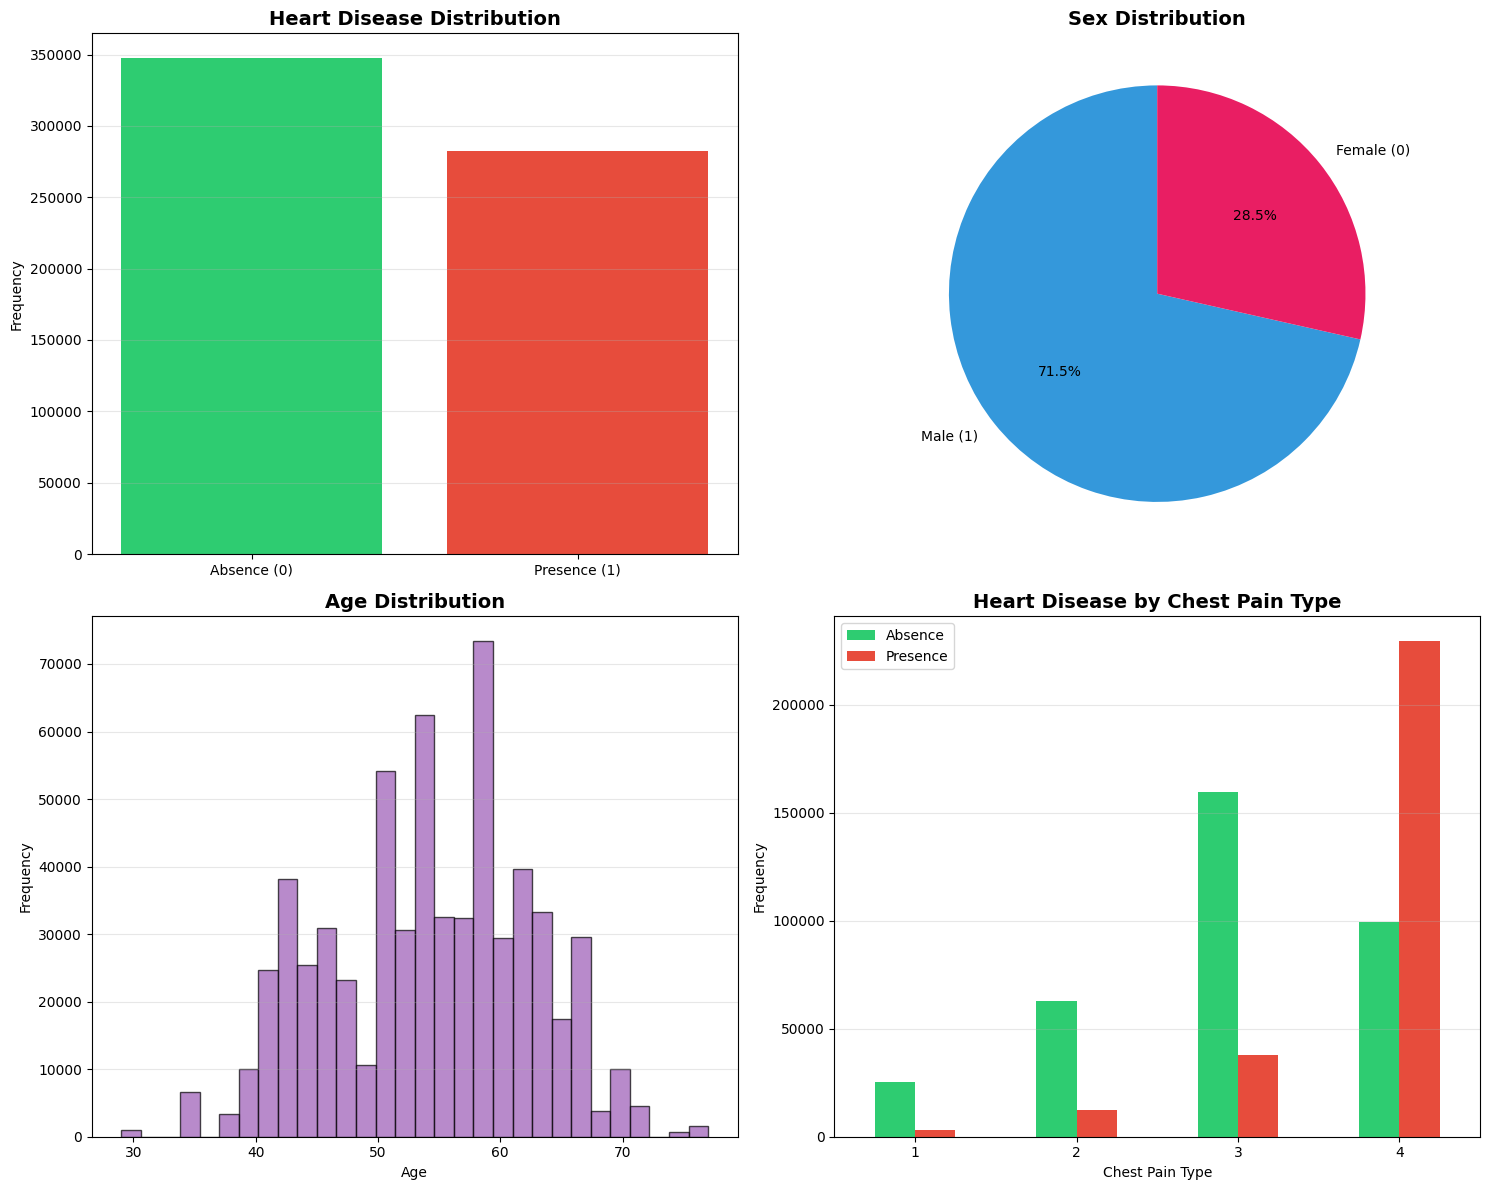


Visualizations completed


In [19]:
# Graphical visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Heart Disease Distribution
axes[0, 0].bar(['Absence (0)', 'Presence (1)'], 
               data_comp['Heart Disease'].value_counts().sort_index(), 
               color=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title('Heart Disease Distribution', fontsize=14, fontweight='bold')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].grid(axis='y', alpha=0.3)

# 2. Sex Distribution
sex_counts = data_comp['Sex'].value_counts()
axes[0, 1].pie(sex_counts, labels=['Male (1)', 'Female (0)'], autopct='%1.1f%%', 
               colors=['#3498db', '#e91e63'], startangle=90)
axes[0, 1].set_title('Sex Distribution', fontsize=14, fontweight='bold')

# 3. Age Distribution
axes[1, 0].hist(data_comp['Age'], bins=30, color='#9b59b6', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Age Distribution', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(axis='y', alpha=0.3)

# 4. Heart Disease by Chest Pain Type
chest_pain_hd = data_comp.groupby('Chest pain type')['Heart Disease'].value_counts().unstack()
chest_pain_hd.plot(kind='bar', ax=axes[1, 1], color=['#2ecc71', '#e74c3c'])
axes[1, 1].set_title('Heart Disease by Chest Pain Type', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Chest Pain Type')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].legend(['Absence', 'Presence'])
axes[1, 1].grid(axis='y', alpha=0.3)
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

print("\nVisualizations completed")

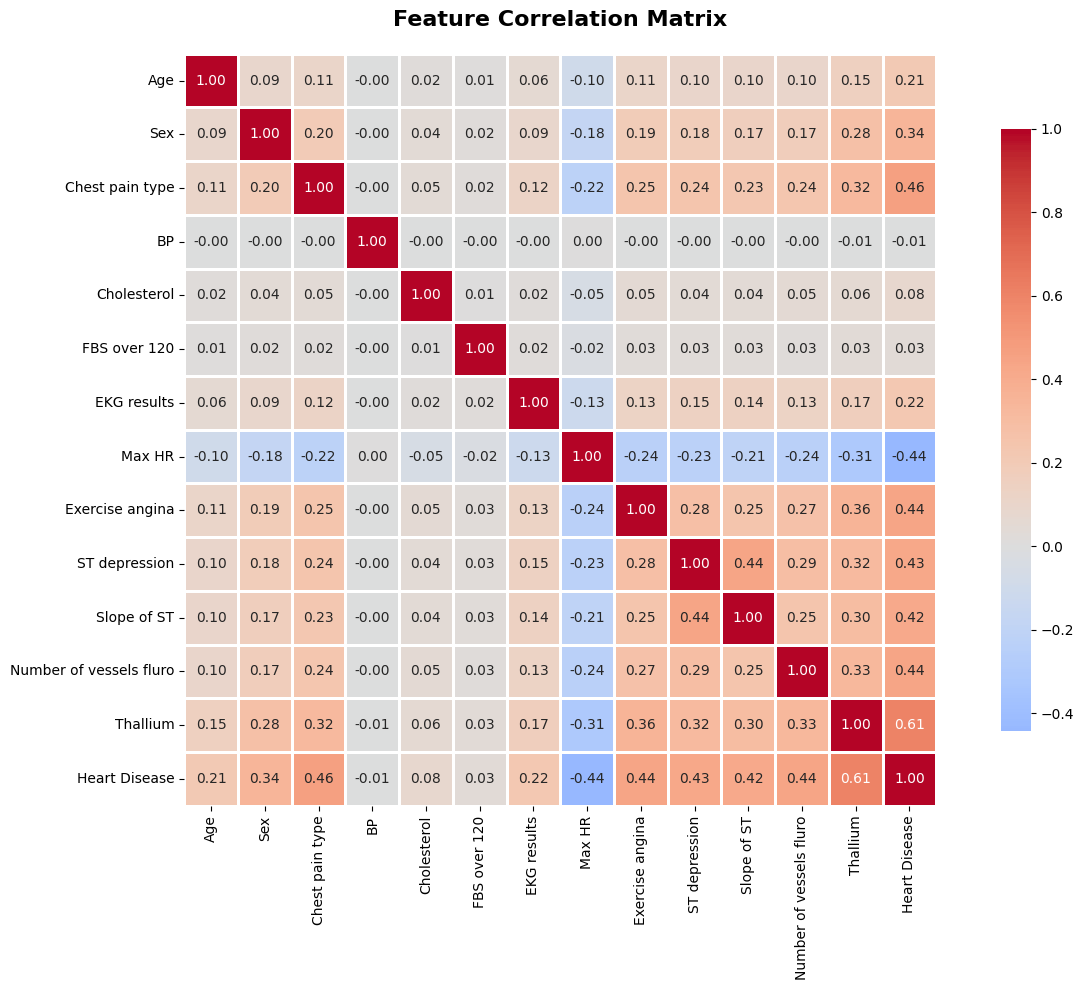


Top features correlated with Heart Disease:
Thallium                   0.605776
Chest pain type            0.460684
Exercise angina            0.441864
Number of vessels fluro    0.438604
ST depression              0.430641
Name: Heart Disease, dtype: float64


In [20]:
# Correlation matrix
plt.figure(figsize=(14, 10))
correlation_matrix = data_comp.drop('id', axis=1).corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Matrix', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\nTop features correlated with Heart Disease:")
hd_corr = correlation_matrix['Heart Disease'].sort_values(ascending=False)
print(hd_corr[1:6])  # Top 5 (excludes correlation with itself)

In [21]:
data_test = pd.read_csv("/kaggle/input/playground-series-s6e2/test.csv")

In [22]:
data_test

,id,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium
0,630000,58,1,3,120,288,0,2,145,1,0.8,2,3,3
1,630001,55,0,2,120,209,0,0,172,0,0.0,1,0,3
2,630002,54,1,4,120,268,0,0,150,1,0.0,2,3,7
3,630003,44,0,3,112,177,0,0,168,0,0.9,1,0,3
4,630004,43,1,1,138,267,0,0,163,0,1.8,2,0,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
269995,899995,58,1,2,120,222,0,0,172,0,1.0,1,0,7
269996,899996,58,1,4,132,289,0,0,172,0,2.8,2,0,3
269997,899997,63,1,3,108,201,1,0,158,0,0.8,1,0,3
269998,899998,59,1,4,120,274,0,2,163,0,0.5,1,0,3


In [23]:
y = list(data_comp["Heart Disease"])

x = []
for i in data_comp.iloc:
    x.append(i[1:-1])

x = np.array(x, dtype = np.float32)
y = np.array(y, dtype = np.float32)

In [24]:
print(y.shape)
print(x.shape)

(630000,)
(630000, 13)


In [25]:
# Set random seed for reproducibility
seed = 42  # You can change this number for different splits

# Shuffle and split into train/test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    x, 
    y,
    test_size=0.2,          # 20% for test
    random_state=seed,      # Seed for reproducibility
    shuffle=True            # Ensure shuffling
)

print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])

Training set size: 504000
Test set size: 126000


In [26]:
def residual_block(x, units):
    # shortcut = x
    out = tf.keras.layers.Dense(units)(x)
    out = tf.keras.layers.BatchNormalization()(out)
    out = tf.keras.layers.ReLU()(out)
    out = tf.keras.layers.Dense(units)(out)
    out = tf.keras.layers.BatchNormalization()(out)
    # Ajustar shortcut si cambian los filtros
    if x.shape[-1] != units:
        out = tf.keras.layers.Dense(x.shape[-1])(out)
        out = tf.keras.layers.BatchNormalization()(out)
    out = tf.keras.layers.Add()([x, out])
    # out = tf.keras.layers.ReLU()(out)
    return out

def build_model(input_dim):
    inputs = tf.keras.Input(shape=(input_dim,))
    
    # Normalización inicial
    x = tf.keras.layers.BatchNormalization()(inputs)
    
    # Bloques residuales
    x = residual_block(x, units=32)
    x = residual_block(x, units=32)
    # x = residual_block(x, units=16)
    
    # Dropout para regularización
    x = tf.keras.layers.Dropout(0.3)(x)
    
    # Regresión logística
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    
    model = tf.keras.Model(inputs, outputs)
    return model

In [27]:
model = build_model(x.shape[1])
model.summary()

I0000 00:00:1793374187.816350      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793374187.822324      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 13)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 13)        │         52 │ input_layer[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        448 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 32)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      1,056 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 13)        │        429 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 13)        │         52 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 13)        │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │        448 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 32)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 32)        │      1,056 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 13)        │        429 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 13)        │         52 │ dense_5[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 13)        │          0 │ add[0][0],        │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 13)        │          0 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         14 │ dropout[0][0]   

 Total params: 4,548 (17.77 KB)

 Trainable params: 4,214 (16.46 KB)

 Non-trainable params: 334 (1.30 KB)

In [28]:
model.compile(
    optimizer = "adamax",
    loss = "mse",
    metrics = ["accuracy", "mae"]
)

In [29]:
# Callback Configuration
print("=" * 60)
print("CALLBACK CONFIGURATION")
print("=" * 60)

# 1. EarlyStopping: Stops training if no improvement
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',           # Metric to monitor
    patience=15,                  # Epochs without improvement before stopping
    restore_best_weights=True,    # Restore best weights
    verbose=1,
    mode='max'
)

# 2. ReduceLROnPlateau: Reduces learning rate when no improvement
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,                   # Reduce LR by half
    patience=7,                   # Epochs without improvement before reducing
    min_lr=1e-7,                  # Minimum learning rate
    verbose=1,
    mode='min'
)

# 3. ModelCheckpoint: Saves best model during training
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_heart_disease_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

# 4. TensorBoard: For TensorBoard visualization (optional)
tensorboard = tf.keras.callbacks.TensorBoard(
    log_dir='./logs',
    histogram_freq=1
)

callbacks_list = [early_stopping, reduce_lr, checkpoint, tensorboard]

print("Callbacks configured:")
print("  - EarlyStopping (patience=15)")
print("  - ReduceLROnPlateau (factor=0.5, patience=7)")
print("  - ModelCheckpoint (saves best model)")
print("  - TensorBoard (logs in ./logs)")
print("=" * 60)

CALLBACK CONFIGURATION
Callbacks configured:
  - EarlyStopping (patience=15)
  - ReduceLROnPlateau (factor=0.5, patience=7)
  - ModelCheckpoint (saves best model)
  - TensorBoard (logs in ./logs)


In [30]:
print("\n" + "=" * 60)
print("STARTING TRAINING")
print("=" * 60 + "\n")

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=64,
    callbacks=callbacks_list,  # Add callbacks
    verbose=0
)

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)


STARTING TRAINING



I0000 00:00:1793374193.646214     129 service.cc:152] XLA service 0x7c66d4003b10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793374193.646247     129 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1793374193.646251     129 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1793374194.308839     129 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1793374196.811198     129 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



Epoch 1: val_accuracy improved from -inf to 0.88293, saving model to best_heart_disease_model.keras

Epoch 2: val_accuracy improved from 0.88293 to 0.88351, saving model to best_heart_disease_model.keras

Epoch 3: val_accuracy improved from 0.88351 to 0.88363, saving model to best_heart_disease_model.keras

Epoch 4: val_accuracy improved from 0.88363 to 0.88410, saving model to best_heart_disease_model.keras

Epoch 5: val_accuracy improved from 0.88410 to 0.88434, saving model to best_heart_disease_model.keras

Epoch 6: val_accuracy improved from 0.88434 to 0.88444, saving model to best_heart_disease_model.keras

Epoch 7: val_accuracy did not improve from 0.88444

Epoch 8: val_accuracy did not improve from 0.88444

Epoch 9: val_accuracy did not improve from 0.88444

Epoch 10: val_accuracy did not improve from 0.88444

Epoch 11: val_accuracy improved from 0.88444 to 0.88454, saving model to best_heart_disease_model.keras

Epoch 12: ReduceLROnPlateau reducing learning rate to 0.00050000


📈 Generating training history plots...


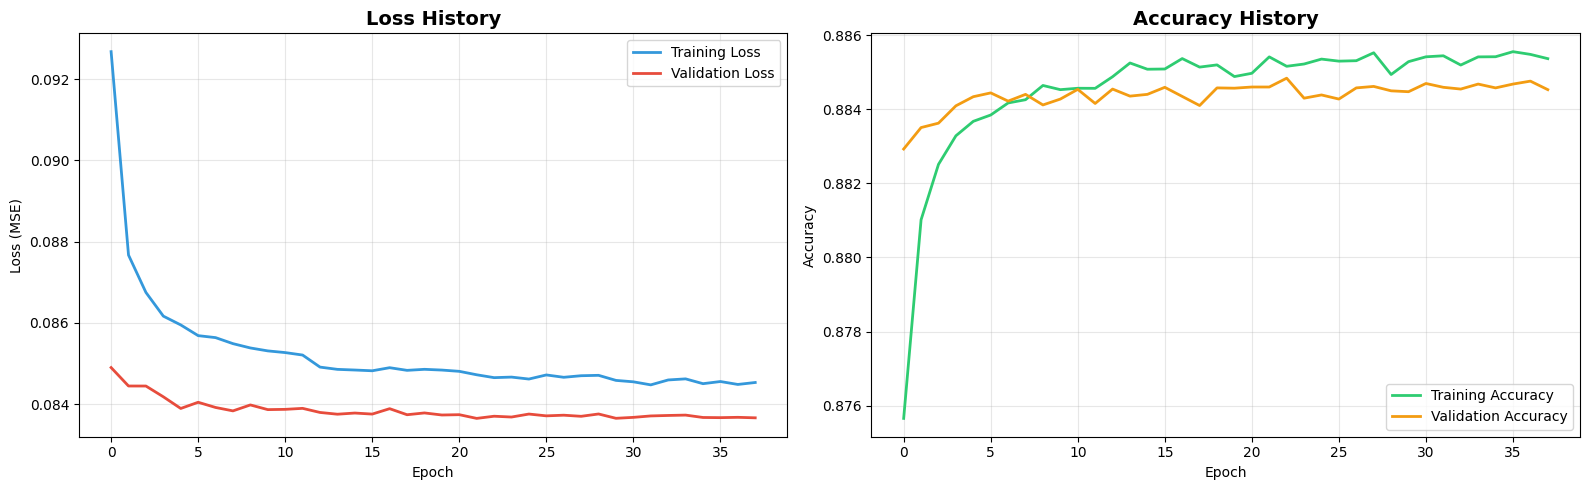


FINAL TRAINING METRICS
  📊 Training Loss:      0.0845
  📊 Validation Loss:    0.0837
  ✅ Training Accuracy:   0.8854 (88.54%)
  ✅ Validation Accuracy: 0.8845 (88.45%)


In [31]:
# Training History Visualization
print("\n📈 Generating training history plots...")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Loss plot
axes[0].plot(history.history['loss'], label='Training Loss', linewidth=2, color='#3498db')
axes[0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2, color='#e74c3c')
axes[0].set_title('Loss History', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MSE)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy plot
axes[1].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2, color='#2ecc71')
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2, color='#f39c12')
axes[1].set_title('Accuracy History', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Show final metrics
final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]
final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]

print("\n" + "=" * 60)
print("FINAL TRAINING METRICS")
print("=" * 60)
print(f"  📊 Training Loss:      {final_train_loss:.4f}")
print(f"  📊 Validation Loss:    {final_val_loss:.4f}")
print(f"  ✅ Training Accuracy:   {final_train_acc:.4f} ({final_train_acc*100:.2f}%)")
print(f"  ✅ Validation Accuracy: {final_val_acc:.4f} ({final_val_acc*100:.2f}%)")
print("=" * 60)

In [32]:
# Model evaluation on test set
print("\n" + "=" * 60)
print("MODEL EVALUATION")
print("=" * 60)

test_loss, test_accuracy, test_mae = model.evaluate(X_test, y_test, batch_size = 512, verbose=0)
print(f"\n📊 Test Loss:     {test_loss:.4f}")
print(f"✅ Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print("=" * 60)


MODEL EVALUATION

📊 Test Loss:     0.0837
✅ Test Accuracy: 0.8848 (88.48%)


In [33]:
# Predictions on test set
print("\n🔮 Generating predictions...")
y_pred_proba = model.predict(X_test, verbose=0, batch_size = 512)
y_pred = (y_pred_proba > 0.5).astype(int).flatten()

print(f"  - Predictions generated: {len(y_pred):,}")
print(f"  - Positive cases predicted: {y_pred.sum():,}")
print(f"  - Negative cases predicted: {(len(y_pred) - y_pred.sum()):,}")

# Some prediction examples
print("\n📋 Prediction Examples:")
print("-" * 60)
print(f"{'Actual':<10} {'Predicted':<10} {'Probability':<15} {'Result'}")
print("-" * 60)
for i in range(10):
    actual = int(y_test[i])
    pred = y_pred[i]
    prob = y_pred_proba[i][0]
    result = "✅ Correct" if actual == pred else "❌ Incorrect"
    print(f"{actual:<10} {pred:<10} {prob:<15.4f} {result}")
print("-" * 60)


🔮 Generating predictions...
  - Predictions generated: 126,000
  - Positive cases predicted: 55,886
  - Negative cases predicted: 70,114

📋 Prediction Examples:
------------------------------------------------------------
Actual     Predicted  Probability     Result
------------------------------------------------------------
0          0          0.2474          ✅ Correct
1          0          0.4063          ❌ Incorrect
1          1          0.9987          ✅ Correct
1          1          0.9938          ✅ Correct
0          0          0.0039          ✅ Correct
0          0          0.1312          ✅ Correct
1          0          0.0082          ❌ Incorrect
1          1          0.9578          ✅ Correct
1          1          0.9988          ✅ Correct
1          1          0.9863          ✅ Correct
------------------------------------------------------------



📊 Generating Confusion Matrix...


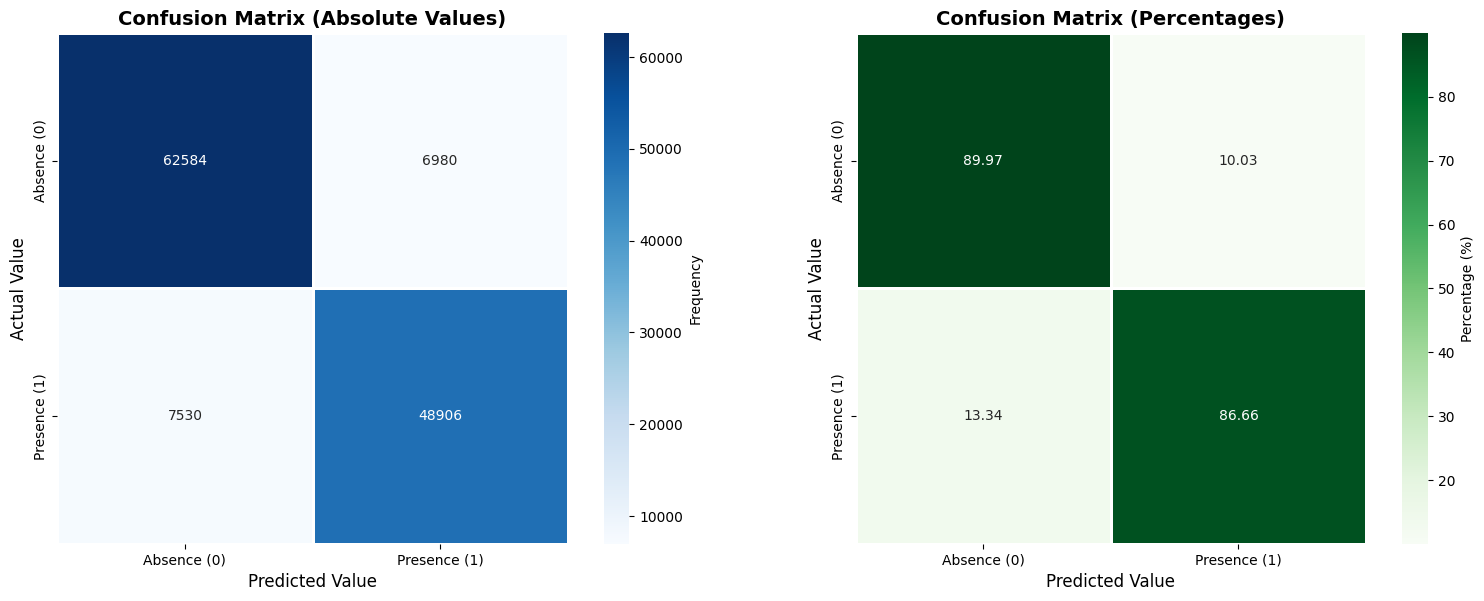


CONFUSION MATRIX ANALYSIS
  True Negatives (TN):  62,584
  False Positives (FP): 6,980
  False Negatives (FN): 7,530
  True Positives (TP):  48,906


In [34]:
# Confusion Matrix
print("\n📊 Generating Confusion Matrix...")

cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion matrix (absolute values)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
            cbar_kws={'label': 'Frequency'}, square=True, linewidths=2)
axes[0].set_title('Confusion Matrix (Absolute Values)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Actual Value', fontsize=12)
axes[0].set_xlabel('Predicted Value', fontsize=12)
axes[0].set_xticklabels(['Absence (0)', 'Presence (1)'])
axes[0].set_yticklabels(['Absence (0)', 'Presence (1)'])

# Confusion matrix (percentages)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
sns.heatmap(cm_percent, annot=True, fmt='.2f', cmap='Greens', ax=axes[1],
            cbar_kws={'label': 'Percentage (%)'}, square=True, linewidths=2)
axes[1].set_title('Confusion Matrix (Percentages)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Actual Value', fontsize=12)
axes[1].set_xlabel('Predicted Value', fontsize=12)
axes[1].set_xticklabels(['Absence (0)', 'Presence (1)'])
axes[1].set_yticklabels(['Absence (0)', 'Presence (1)'])

plt.tight_layout()
plt.show()

# Confusion matrix interpretation
tn, fp, fn, tp = cm.ravel()
print("\n" + "=" * 60)
print("CONFUSION MATRIX ANALYSIS")
print("=" * 60)
print(f"  True Negatives (TN):  {tn:,}")
print(f"  False Positives (FP): {fp:,}")
print(f"  False Negatives (FN): {fn:,}")
print(f"  True Positives (TP):  {tp:,}")
print("=" * 60)

In [35]:
# Classification Report
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=['Absence (0)', 'Presence (1)']))

# Additional metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("=" * 60)
print("ADDITIONAL METRICS")
print("=" * 60)
print(f"  Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"  Recall:    {recall:.4f} ({recall*100:.2f}%)")
print(f"  F1-Score:  {f1:.4f} ({f1*100:.2f}%)")
print("=" * 60)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Absence (0)       0.89      0.90      0.90     69564
Presence (1)       0.88      0.87      0.87     56436

    accuracy                           0.88    126000
   macro avg       0.88      0.88      0.88    126000
weighted avg       0.88      0.88      0.88    126000

ADDITIONAL METRICS
  Precision: 0.8751 (87.51%)
  Recall:    0.8666 (86.66%)
  F1-Score:  0.8708 (87.08%)



📈 Generating ROC Curve...


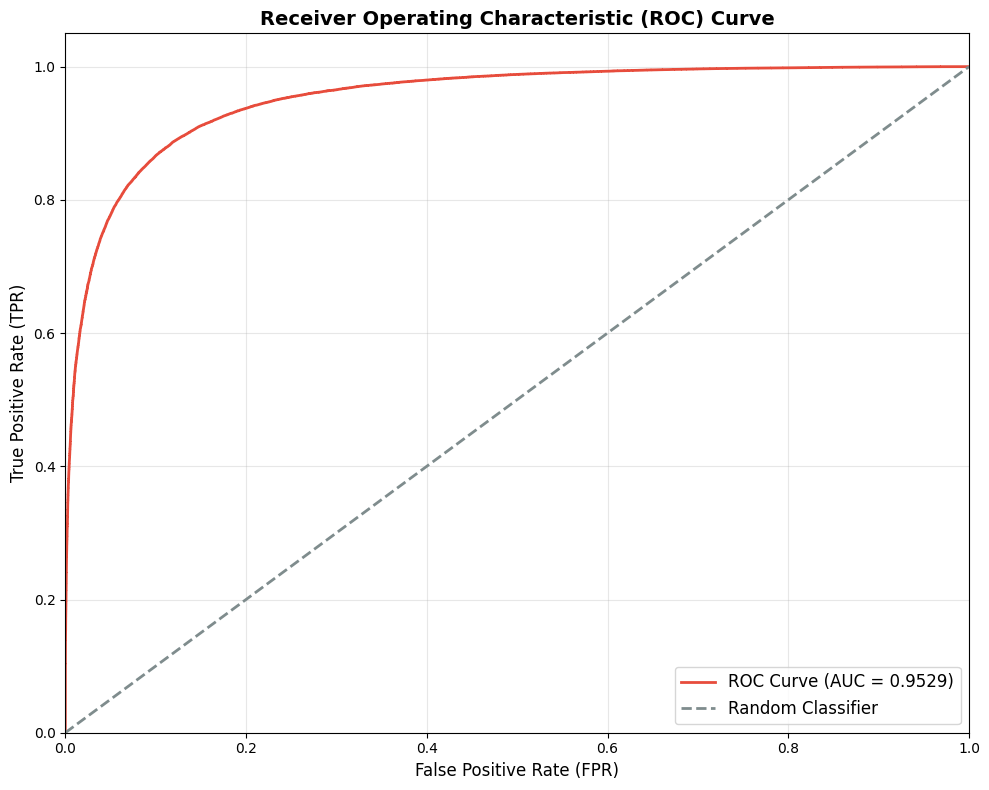


🎯 AUC Score: 0.9529 (95.29%)

AUC Interpretation:
  ⭐ Excellent: The model has outstanding performance


In [36]:
# ROC Curve and AUC
print("\n📈 Generating ROC Curve...")

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='#e74c3c', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='#7f8c8d', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n🎯 AUC Score: {roc_auc:.4f} ({roc_auc*100:.2f}%)")
print("\nAUC Interpretation:")
if roc_auc >= 0.9:
    print("  ⭐ Excellent: The model has outstanding performance")
elif roc_auc >= 0.8:
    print("  ✅ Good: The model has good performance")
elif roc_auc >= 0.7:
    print("  ⚠️ Acceptable: The model has acceptable performance")
else:
    print("  ❌ Poor: The model needs improvement")

In [37]:
# Model saving
print("\n" + "=" * 60)
print("SAVING MODEL")
print("=" * 60)

# Save complete model
model_path = 'heart_disease_model_final.keras'
model.save(model_path)
print(f"Model saved at: {model_path}")

# Save weights only
weights_path = 'heart_disease_model_weights.weights.h5'
model.save_weights(weights_path)
print(f"Weights saved at: {weights_path}")

# Save architecture as JSON
model_json = model.to_json()
with open('heart_disease_model_architecture.json', 'w') as json_file:
    json_file.write(model_json)
print(f"Architecture saved at: heart_disease_model_architecture.json")

print("\nGenerated files:")
print("  1. best_heart_disease_model.keras (best model during training)")
print("  2. heart_disease_model_final.keras (final model)")
print("  3. heart_disease_model_weights.weights.h5 (weights only)")
print("  4. heart_disease_model_architecture.json (architecture)")
print("=" * 60)


SAVING MODEL
Model saved at: heart_disease_model_final.keras
Weights saved at: heart_disease_model_weights.weights.h5
Architecture saved at: heart_disease_model_architecture.json

Generated files:
  1. best_heart_disease_model.keras (best model during training)
  2. heart_disease_model_final.keras (final model)
  3. heart_disease_model_weights.weights.h5 (weights only)
  4. heart_disease_model_architecture.json (architecture)


In [38]:
# Load saved model (example)
print("\n" + "=" * 60)
print("VERIFYING MODEL LOADING")
print("=" * 60)

# Load the model
loaded_model = tf.keras.models.load_model(model_path)
print(f"Model successfully loaded from: {model_path}")

# Verify it works correctly
loaded_predictions = loaded_model.predict(X_test[:5], verbose=0)
print("\nLoaded model predictions (first 5 examples):")
for i, pred in enumerate(loaded_predictions):
    print(f"  Example {i+1}: {pred[0]:.4f} -> Class: {int(pred[0] > 0.5)}")

print("\nModel loaded and working correctly")
print("=" * 60)


VERIFYING MODEL LOADING
Model successfully loaded from: heart_disease_model_final.keras

Loaded model predictions (first 5 examples):
  Example 1: 0.2474 -> Class: 0
  Example 2: 0.4063 -> Class: 0
  Example 3: 0.9987 -> Class: 1
  Example 4: 0.9938 -> Class: 1
  Example 5: 0.0039 -> Class: 0

Model loaded and working correctly


In [39]:
# Predictions for competition set
print("\n" + "=" * 60)
print("GENERATING PREDICTIONS")
print("=" * 60)

# Prepare test data
x_comp = []
for i in data_test.iloc:
    x_comp.append(i[1:])  # Exclude only the id

x_comp = np.array(x_comp, dtype=np.float32)

print(f"📊 Competition data: {x_comp.shape}")

# Generate predictions
predictions_comp = model.predict(x_comp, verbose=1, batch_size = 512)
predictions_comp_binary = (predictions_comp > 0.5).astype(int).flatten()

# Map back to labels
predictions_labels = ['Presence' if p == 1 else 'Absence' for p in predictions_comp_binary]

print(f"\nPredictions generated:")
print(f"  - Total: {len(predictions_labels):,}")
print(f"  - Presence: {predictions_comp_binary.sum():,}")
print(f"  - Absence: {len(predictions_labels) - predictions_comp_binary.sum():,}")

# Create submission file
submission = pd.DataFrame({
    'id': data_test['id'],
    'Heart Disease': predictions_comp.reshape(len(predictions_comp))
})

submission.to_csv('submission.csv', index=False)
print(f"\n💾 Submission file saved: submission.csv")
print("\n📋 First 10 predictions:")
print(submission.head(10))
print("=" * 60)


GENERATING PREDICTIONS
📊 Competition data: (270000, 13)
528/528 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Predictions generated:
  - Total: 270,000
  - Presence: 120,155
  - Absence: 149,845

💾 Submission file saved: submission.csv

📋 First 10 predictions:
       id  Heart Disease
0  630000       0.935680
1  630001       0.000631
2  630002       0.996277
3  630003       0.000907
4  630004       0.388409
5  630005       0.995107
6  630006       0.007916
7  630007       0.689176
8  630008       0.998205
9  630009       0.003543


In [40]:
# Final Summary
print("\n" + "=" * 80)
print(" " * 25 + "🎉 FINAL SUMMARY 🎉")
print("=" * 80)

print("\n📊 MODEL METRICS:")
print(f"  • Test Accuracy:     {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"  • Precision:         {precision:.4f} ({precision*100:.2f}%)")
print(f"  • Recall:            {recall:.4f} ({recall*100:.2f}%)")
print(f"  • F1-Score:          {f1:.4f} ({f1*100:.2f}%)")
print(f"  • AUC Score:         {roc_auc:.4f} ({roc_auc*100:.2f}%)")

print("\n💾 GENERATED FILES:")
print("  1️⃣  best_heart_disease_model.keras - Best model during training")
print("  2️⃣  heart_disease_model_final.keras - Final model")
print("  3️⃣  heart_disease_model_weights.weights.h5 - Model weights only")
print("  4️⃣  heart_disease_model_architecture.json - Model architecture")
print("  5️⃣  submission.csv - Kaggle predictions")

print("\n" + "=" * 80)


                         🎉 FINAL SUMMARY 🎉

📊 MODEL METRICS:
  • Test Accuracy:     0.8848 (88.48%)
  • Precision:         0.8751 (87.51%)
  • Recall:            0.8666 (86.66%)
  • F1-Score:          0.8708 (87.08%)
  • AUC Score:         0.9529 (95.29%)

💾 GENERATED FILES:
  1️⃣  best_heart_disease_model.keras - Best model during training
  2️⃣  heart_disease_model_final.keras - Final model
  3️⃣  heart_disease_model_weights.weights.h5 - Model weights only
  4️⃣  heart_disease_model_architecture.json - Model architecture
  5️⃣  submission.csv - Kaggle predictions

